# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

**Carga del dataset e identificación de documentos**

In [7]:
from pathlib import Path
import nltk
from nltk.corpus import gutenberg

root_dir = Path.cwd().resolve()
if root_dir.name == "notebooks":
    root_dir = root_dir.parent
ruta = str(root_dir / "data" / "nltk_data")
if ruta not in nltk.data.path:
    nltk.data.path.insert(0, ruta)

documentos = gutenberg.fileids()
print("Cantidad:", len(documentos))

for doc_id in documentos:
    kb = Path(gutenberg.abspath(doc_id)).stat().st_size / 1024
    print(f"{doc_id}: {kb:.1f} KB")

Cantidad: 18
austen-emma.txt: 866.3 KB
austen-persuasion.txt: 455.4 KB
austen-sense.txt: 657.2 KB
bible-kjv.txt: 4231.0 KB
blake-poems.txt: 37.3 KB
bryant-stories.txt: 243.6 KB
burgess-busterbrown.txt: 82.7 KB
carroll-alice.txt: 141.0 KB
chesterton-ball.txt: 446.7 KB
chesterton-brown.txt: 397.1 KB
chesterton-thursday.txt: 313.0 KB
edgeworth-parents.txt: 913.2 KB
melville-moby_dick.txt: 1213.9 KB
milton-paradise.txt: 457.2 KB
shakespeare-caesar.txt: 109.7 KB
shakespeare-hamlet.txt: 159.1 KB
shakespeare-macbeth.txt: 98.0 KB
whitman-leaves.txt: 694.5 KB


**Tokenización y limpieza de caracteres**

Configuración aplicada en todos los experimentos:
- Se convierten los textos a minúsculas antes de tokenizar.
- `RegexpTokenizer(r"[A-Za-z]+(?:['’][A-Za-z]+)?")` conserva secuencias de letras ASCII y apóstrofos internos; otros signos, incluidos los guiones, separan tokens.
- No se eliminan stopwords ni se aplica stemming o lematización.
- El patrón no incluye dígitos ni letras acentuadas; esta limitación se mantiene igual para los documentos y las consultas.

- Se reutiliza la misma tokenización para cada operando de consulta; se rechazan entradas sin tokens o con más de uno. AND y OR reciben dos operandos y NOT recibe uno.


In [8]:
from nltk.tokenize import RegexpTokenizer

tokenizador = RegexpTokenizer(r"[A-Za-z]+(?:['’][A-Za-z]+)?")


def tokenizar(texto):
    return tokenizador.tokenize(texto.lower())


def normalizar_termino(termino):
    termino = termino.strip().lower()
    # Un término formado solo por letras ASCII ya es un token válido.
    if termino.isascii() and termino.isalpha():
        return termino
    tokens = tokenizar(termino)
    if len(tokens) != 1:
        raise ValueError("Cada operando debe contener un único término válido.")
    return tokens[0]


corpus_procesado = {}
for doc_id in documentos:
    corpus_procesado[doc_id] = tokenizar(gutenberg.raw(doc_id))

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [9]:
def busqueda_secuencial(termino):
    termino = normalizar_termino(termino)
    resultado = []

    for doc_id, tokens in corpus_procesado.items():
        for token in tokens:
            if token == termino:
                resultado.append(doc_id)
                break
    return resultado

In [10]:
consultas = {
    "frecuente": "he",
    "poco frecuente": "moby",
    "inexistente": "tinitana",
}

for categoria, termino in consultas.items():
    resultados = busqueda_secuencial(termino)
    print(f"{categoria} ({termino}): ",resultados)

frecuente (he):  ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
poco frecuente (moby):  ['melville-moby_dick.txt']
inexistente (tinitana):  []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [11]:
import time


def medir_consulta(funcion_busqueda, *terminos, repeticiones=30):
    if repeticiones <= 0:
        raise ValueError("El número de repeticiones debe ser positivo.")

    tiempos_ms = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion_busqueda(*terminos)
        fin = time.perf_counter_ns()
        tiempos_ms.append((fin - inicio) / 1_000_000)

    return sum(tiempos_ms) / repeticiones

In [12]:
for categoria, termino in consultas.items():
    promedio_ms = medir_consulta(busqueda_secuencial, termino, repeticiones=30)
    cantidad_documentos = len(busqueda_secuencial(termino))
    print(
        f"{categoria} ({termino}): {cantidad_documentos} documentos; "
        f"promedio = {promedio_ms:.4f} ms"
    )

frecuente (he): 18 documentos; promedio = 0.1249 ms
poco frecuente (moby): 1 documentos; promedio = 37.5481 ms
inexistente (tinitana): 0 documentos; promedio = 38.7151 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.


Los postings se almacenan como conjuntos para aplicar directamente intersección (`&`, AND), unión (`|`, OR) y diferencia respecto al universo (`-`, NOT). El universo se calcula una vez. Las consultas devuelven listas ordenadas, sin modificar el índice; el ordenamiento de la salida también forma parte del tiempo medido.

Los conjuntos evitan reconstruir los postings en cada consulta, a cambio de mayor memoria que las listas ordenadas. Para el corpus grande habrá que medir también este costo.


In [13]:
from collections import defaultdict

# Los conjuntos se construyen una sola vez; cada documento aparece una vez por término.
indice_invertido = defaultdict(set)
universo_documentos = set(corpus_procesado)
postings_vacios = frozenset()

for doc_id, tokens in corpus_procesado.items():
    for termino in set(tokens):
        indice_invertido[termino].add(doc_id)

In [14]:
import pandas as pd

# La matriz es solo una visualización: materializamos únicamente la muestra.
terminos_muestra = sorted(indice_invertido)[:18]
documentos_muestra = list(corpus_procesado)[:18]
matriz = pd.DataFrame(
    [
        [doc_id in indice_invertido[termino] for doc_id in documentos_muestra]
        for termino in terminos_muestra
    ],
    index=terminos_muestra,
    columns=documentos_muestra,
    dtype="int8",
)

print(
    "Tamaño completo (términos, documentos):",
    (len(indice_invertido), len(universo_documentos)),
)
print("Muestra materializada:", matriz.shape)
display(matriz)

Tamaño completo (términos, documentos): (43495, 18)
Muestra materializada: (18, 18)


,austen-emma.txt,austen-persuasion.txt,austen-sense.txt,bible-kjv.txt,blake-poems.txt,bryant-stories.txt,burgess-busterbrown.txt,carroll-alice.txt,chesterton-ball.txt,chesterton-brown.txt,chesterton-thursday.txt,edgeworth-parents.txt,melville-moby_dick.txt,milton-paradise.txt,shakespeare-caesar.txt,shakespeare-hamlet.txt,shakespeare-macbeth.txt,whitman-leaves.txt
a,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
a'lee,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
a'low,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
a'm,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
a'most,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
a'n,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
a'ready,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
a'shiver,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
a'th,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
a'top,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [15]:
def consulta_termino(termino):
    return sorted(indice_invertido.get(normalizar_termino(termino), postings_vacios))


def consulta_and(termino_1, termino_2):
    postings_1 = indice_invertido.get(normalizar_termino(termino_1), postings_vacios)
    postings_2 = indice_invertido.get(normalizar_termino(termino_2), postings_vacios)
    return sorted(postings_1 & postings_2)


def consulta_or(termino_1, termino_2):
    postings_1 = indice_invertido.get(normalizar_termino(termino_1), postings_vacios)
    postings_2 = indice_invertido.get(normalizar_termino(termino_2), postings_vacios)
    return sorted(postings_1 | postings_2)


def consulta_not(termino):
    postings = indice_invertido.get(normalizar_termino(termino), postings_vacios)
    return sorted(universo_documentos - postings)


terminos_df = ["he", "science", "moby", "tinitana"]
resumen_postings = []
for termino in terminos_df:
    postings = consulta_termino(termino)
    resumen_postings.append({"término": termino, "postings": postings, "DF": len(postings)})
display(pd.DataFrame(resumen_postings))

print("Consulta de un término (moby):", consulta_termino("moby"))
print("science AND whale:", consulta_and("science", "whale"))
print("science OR whale:", consulta_or("science", "whale"))
print("NOT science:", consulta_not("science"))

,término,postings,DF
0,he,"[austen-emma.txt, austen-persuasion.txt, auste...",18
1,science,"[bible-kjv.txt, chesterton-ball.txt, chesterto...",8
2,moby,[melville-moby_dick.txt],1
3,tinitana,[],0


Consulta de un término (moby): ['melville-moby_dick.txt']
science AND whale: ['bible-kjv.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'whitman-leaves.txt']
science OR whale: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
NOT science: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt']


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

La carga del corpus, la tokenización y la construcción del índice ocurren antes de medir las consultas.


Se comparan consultas simples y booleanas, incluidos términos inexistentes. Para las booleanas secuenciales se combinan los resultados de las búsquedas del punto 2, sin consultar el índice. La igualdad se comprueba por identificadores, independientemente de su orden, y una discrepancia detiene la comparación. Los tiempos son medias por consulta; no incluyen la presentación de la tabla.


In [16]:
def consulta_and_secuencial(termino_1, termino_2):
    documentos_1 = set(busqueda_secuencial(termino_1))
    documentos_2 = set(busqueda_secuencial(termino_2))
    return sorted(documentos_1 & documentos_2)


def consulta_or_secuencial(termino_1, termino_2):
    documentos_1 = set(busqueda_secuencial(termino_1))
    documentos_2 = set(busqueda_secuencial(termino_2))
    return sorted(documentos_1 | documentos_2)


def consulta_not_secuencial(termino):
    return sorted(set(corpus_procesado) - set(busqueda_secuencial(termino)))


casos_comparacion = [
    (f"{categoria} ({termino})", busqueda_secuencial, consulta_termino, (termino,))
    for categoria, termino in consultas.items()
]
casos_comparacion.extend([
    ("science AND whale", consulta_and_secuencial, consulta_and, ("science", "whale")),
    ("science OR whale", consulta_or_secuencial, consulta_or, ("science", "whale")),
    ("NOT science", consulta_not_secuencial, consulta_not, ("science",)),
    ("science AND tinitana", consulta_and_secuencial, consulta_and, ("science", "tinitana")),
    ("science OR tinitana", consulta_or_secuencial, consulta_or, ("science", "tinitana")),
    ("NOT tinitana", consulta_not_secuencial, consulta_not, ("tinitana",)),
])

comparacion = []
for consulta, metodo_secuencial, metodo_indice, terminos in casos_comparacion:
    resultados_secuencial = metodo_secuencial(*terminos)
    resultados_indice = metodo_indice(*terminos)
    mismos_documentos = set(resultados_secuencial) == set(resultados_indice)
    assert mismos_documentos, f"Los métodos difieren para: {consulta}"

    comparacion.append({
        "Consulta": consulta,
        "Mismos documentos": mismos_documentos,
        "Documentos": len(resultados_indice),
        "Secuencial (ms)": medir_consulta(metodo_secuencial, *terminos, repeticiones=30),
        "Índice (ms)": medir_consulta(metodo_indice, *terminos, repeticiones=30),
    })

comparacion = pd.DataFrame(comparacion)
display(comparacion.round(6))

,Consulta,Mismos documentos,Documentos,Secuencial (ms),Índice (ms)
0,frecuente (he),True,18,0.135253,0.001127
1,poco frecuente (moby),True,1,38.591100,0.000913
2,inexistente (tinitana),True,0,39.124723,0.000750
3,science AND whale,True,4,47.327650,0.001500
4,science OR whale,True,10,45.981610,0.001553
5,NOT science,True,10,22.766933,0.001900
6,science AND tinitana,True,0,62.867180,0.001030
7,science OR tinitana,True,8,61.650580,0.001363
8,NOT tinitana,True,18,38.960633,0.001620


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [3]:
import zipfile
import tarfile

carpeta = root_dir / "data" / "large_gutenberg"
archivo_zip = carpeta / "txt-files.tar.zip"
archivo_tar = carpeta / "txt-files.tar"
carpeta_textos = carpeta / "txt"

print("Extrayendo el ZIP...")
with zipfile.ZipFile(archivo_zip) as comprimido:
    comprimido.extract("txt-files.tar", path=carpeta)

print("Extrayendo los archivos del TAR...")
with tarfile.open(archivo_tar, "r:") as comprimido:
    comprimido.extractall(path=carpeta_textos, filter="data")

print("Extracción terminada:", carpeta_textos)

Extrayendo el ZIP...
Extrayendo los archivos del TAR...
Extracción terminada: C:\Users\johan\Desktop\UNI\7 Semestre\Recuperación_de_Información\data\large_gutenberg\txt


In [4]:
import csv
from pathlib import Path

carpeta_corpus = root_dir / "data" / "large_gutenberg"
carpeta_libros = carpeta_corpus / "txt" / "cache" / "epub"

if not carpeta_libros.is_dir():
    raise FileNotFoundError(f"No existe la carpeta extraída: {carpeta_libros}")

carpetas = sorted(
    (
        carpeta
        for carpeta in carpeta_libros.iterdir()
        if carpeta.is_dir() and carpeta.name.isdigit()
    ),
    key=lambda carpeta: int(carpeta.name),
)

documentos_grandes = {}
registros = []
sin_documento_valido = []
total_txt = 0

for carpeta in carpetas:
    doc_id = carpeta.name

    candidatos = sorted(
        (
            archivo
            for archivo in carpeta.iterdir()
            if archivo.is_file() and archivo.suffix.lower() == ".txt"
        ),
        key=lambda archivo: (
            archivo.name.lower() != f"pg{doc_id}.txt",
            archivo.name.lower(),
        ),
    )
    total_txt += len(candidatos)

    for archivo in candidatos:
        try:
            with archivo.open("rb") as contenido:
                if not contenido.read(1):
                    continue
            tamano = archivo.stat().st_size
        except OSError:
            continue

        documentos_grandes[doc_id] = archivo
        registros.append({
            "doc_id": doc_id,
            "ruta": archivo.relative_to(root_dir).as_posix(),
            "bytes": tamano,
        })
        break
    else:
        sin_documento_valido.append(doc_id)

archivo_manifest = carpeta_corpus / "documentos_validos.csv"

with archivo_manifest.open("w", encoding="utf-8", newline="") as salida:
    escritor = csv.DictWriter(salida, fieldnames=["doc_id", "ruta", "bytes"])
    escritor.writeheader()
    escritor.writerows(registros)

print("Carpetas con ID de Gutenberg:", len(carpetas))
print("Archivos TXT encontrados:", total_txt)
print("Documentos válidos seleccionados:", len(documentos_grandes))
print("TXT no seleccionados:", total_txt - len(documentos_grandes))
print("IDs sin un TXT válido:", len(sin_documento_valido))
print(
    "Tamaño de los TXT seleccionados:",
    f"{sum(registro['bytes'] for registro in registros) / 1_000_000_000:.2f} GB",
)
print("Inventario guardado en:", archivo_manifest)

Carpetas con ID de Gutenberg: 78107
Archivos TXT encontrados: 78107
Documentos válidos seleccionados: 78107
TXT no seleccionados: 0
IDs sin un TXT válido: 0
Tamaño de los TXT seleccionados: 30.55 GB
Inventario guardado en: C:\Users\johan\Desktop\UNI\7 Semestre\Recuperación_de_Información\data\large_gutenberg\documentos_validos.csv


Se encontraron 78.107 archivos TXT distribuidos en carpetas identificadas
con el ID de Gutenberg. Para el inventario se consideró válido un archivo
que pudiera abrirse y tuviera contenido.

Se seleccionó un TXT por identificador para evitar contar sus distintas
versiones como documentos separados. En esta descarga se encontró un
solo TXT por carpeta, por lo que no fue necesario descartar versiones
adicionales.

Esta revisión comprueba el acceso y que los archivos no estén vacíos.
La lectura completa y la comprobación de su codificación se realizan
después, sobre los documentos seleccionados para el experimento.

**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [22]:
import csv
import random
import time
from collections import defaultdict
from functools import partial

import pandas as pd
import psutil


def busqueda_secuencial(termino, corpus=None):
    if corpus is None:
        corpus = corpus_procesado

    termino = normalizar_termino(termino)
    resultado = []

    for doc_id, tokens in corpus.items():
        for token in tokens:
            if token == termino:
                resultado.append(doc_id)
                break

    return resultado


def consulta_termino(termino, indice=None):
    if indice is None:
        indice = indice_invertido

    return sorted(indice.get(normalizar_termino(termino), ()))


def construir_indice(corpus):
    indice = defaultdict(set)

    for doc_id, tokens in corpus.items():
        for termino in set(tokens):
            indice[termino].add(doc_id)

    return indice


carpeta_corpus = root_dir / "data" / "large_gutenberg"

with (carpeta_corpus / "documentos_validos.csv").open(
    encoding="utf-8", newline=""
) as entrada:
    inventario = list(csv.DictReader(entrada))

tamanos = [50, 100, 250, 500, 1000]
repeticiones = 30
terminos_consulta = ["he", "moby", "tinitana"]

if len(inventario) < max(tamanos):
    raise ValueError("El inventario no contiene suficientes documentos.")

seleccion = random.Random(42).sample(inventario, max(tamanos))
pd.DataFrame(seleccion).to_csv(
    carpeta_corpus / "seleccion_punto7.csv", index=False
)

corpus_grande = {}
resultados_grandes = []
recursos_grandes = []

tokens_acumulados = 0
bytes_acumulados = 0
preparacion_acumulada_s = 0.0
proceso = psutil.Process()

for n in tamanos:
    inicio = time.perf_counter()

    for registro in seleccion[len(corpus_grande):n]:
        ruta = root_dir / registro["ruta"]
        texto = ruta.read_text(encoding="utf-8-sig")
        tokens = tokenizar(texto)

        corpus_grande[registro["doc_id"]] = tokens
        tokens_acumulados += len(tokens)
        bytes_acumulados += ruta.stat().st_size

        if len(corpus_grande) % 50 == 0:
            print(
                f"Documentos preparados: {len(corpus_grande)}",
                flush=True,
            )

    preparacion_acumulada_s += time.perf_counter() - inicio
    del texto, tokens

    buscar_secuencial = partial(busqueda_secuencial, corpus=corpus_grande)
    resultados_secuenciales = {}
    tiempos_secuenciales = {}

    for termino in terminos_consulta:
        resultados_secuenciales[termino] = buscar_secuencial(termino)
        tiempos_secuenciales[termino] = medir_consulta(
            buscar_secuencial, termino, repeticiones=repeticiones
        )

    inicio = time.perf_counter()
    indice_grande = construir_indice(corpus_grande)
    construccion_indice_s = time.perf_counter() - inicio

    recursos_grandes.append({
        "Documentos": n,
        "Tokens": tokens_acumulados,
        "TXT_MiB": bytes_acumulados / 1024**2,
        "RAM_proceso_MiB": proceso.memory_info().rss / 1024**2,
        "Preparacion_acumulada_s": preparacion_acumulada_s,
        "Construccion_indice_s": construccion_indice_s,
    })

    buscar_indice = partial(consulta_termino, indice=indice_grande)

    for termino in terminos_consulta:
        secuencial = resultados_secuenciales[termino]
        indexado = buscar_indice(termino)

        if set(secuencial) != set(indexado):
            raise AssertionError(
                f"Resultados distintos: n={n}, término={termino}"
            )

        resultados_grandes.append({
            "Documentos": n,
            "Tokens": tokens_acumulados,
            "Consulta": termino,
            "Recuperados": len(indexado),
            "Coinciden": True,
            "Secuencial_ms": tiempos_secuenciales[termino],
            "Indice_ms": medir_consulta(
                buscar_indice, termino, repeticiones=repeticiones
            ),
        })

    print(f"Comparación terminada para {n} documentos.", flush=True)
    del buscar_indice, indice_grande

resultados_grandes = pd.DataFrame(resultados_grandes)
recursos_grandes = pd.DataFrame(recursos_grandes)

resultados_grandes.to_csv(
    carpeta_corpus / "resultados_punto7.csv", index=False
)
recursos_grandes.to_csv(
    carpeta_corpus / "recursos_punto7.csv", index=False
)

display(resultados_grandes.round(6))
display(recursos_grandes.round(3))

Documentos preparados: 50
Comparación terminada para 50 documentos.
Documentos preparados: 100
Comparación terminada para 100 documentos.
Documentos preparados: 150
Documentos preparados: 200
Documentos preparados: 250
Comparación terminada para 250 documentos.
Documentos preparados: 300
Documentos preparados: 350
Documentos preparados: 400
Documentos preparados: 450
Documentos preparados: 500
Comparación terminada para 500 documentos.
Documentos preparados: 550
Documentos preparados: 600
Documentos preparados: 650
Documentos preparados: 700
Documentos preparados: 750
Documentos preparados: 800
Documentos preparados: 850
Documentos preparados: 900
Documentos preparados: 950
Documentos preparados: 1000
Comparación terminada para 1000 documentos.


,Documentos,Tokens,Consulta,Recuperados,Coinciden,Secuencial_ms,Indice_ms
0,50,3715286,he,50,True,10.510463,0.002067
1,50,3715286,moby,1,True,72.177697,0.000567
2,50,3715286,tinitana,0,True,69.208330,0.000563
3,100,6476824,he,100,True,21.519730,0.004403
4,100,6476824,moby,1,True,125.074937,0.000630
5,100,6476824,tinitana,0,True,118.360413,0.000587
6,250,16309208,he,250,True,42.626810,0.017240
7,250,16309208,moby,1,True,313.304440,0.000970
8,250,16309208,tinitana,0,True,310.182640,0.000870
9,500,31558059,he,500,True,79.835033,0.026210


,Documentos,Tokens,TXT_MiB,RAM_proceso_MiB,Preparacion_acumulada_s,Construccion_indice_s
0,50,3715286,22.169,4305.668,1.506,0.384
1,100,6476824,37.853,4471.105,2.633,1.299
2,250,16309208,95.888,5075.496,6.545,1.842
3,500,31558059,185.222,6022.234,13.088,4.499
4,1000,62744761,369.210,7953.277,25.880,8.905


Se trabajó con subconjuntos de 50, 100, 250, 500 y 1.000 documentos,
conservando sus identificadores de Gutenberg. La selección utiliza
la semilla 42 para poder repetir el experimento con los mismos libros.
Cada subconjunto amplía el anterior y reutiliza los documentos ya
procesados.

Se aplicó la misma normalización de la Parte A. Primero se midieron
las consultas secuenciales; después se construyó el índice de cada
subconjunto y se midieron las consultas indexadas. Cada tiempo es
la media de 30 ejecuciones. La lectura, la tokenización y la construcción
del índice quedaron fuera del tiempo de consulta.

La igualdad se comprobó comparando los identificadores recuperados,
sin depender de su orden.

En la tabla de recursos, TXT_MiB indica el tamaño de los archivos
seleccionados en disco; no incluye el ZIP, el TAR ni los resultados
generados. RAM_proceso_MiB muestra la memoria total que ocupaba
el proceso de Python después de construir el índice. Esa lectura
incluye el resto de variables de la sesión y no representa la memoria
exclusiva del corpus ni el máximo alcanzado durante la ejecución.

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Medición terminada: 50 documentos.
Medición terminada: 100 documentos.
Medición terminada: 250 documentos.
Medición terminada: 500 documentos.
Medición terminada: 1000 documentos.


,Documentos,Tokens,Consulta,Secuencial_ms,Indice_ms
0,50,3715286,tinitana,70.399403,0.001080
1,100,6476824,tinitana,117.678570,0.001070
2,250,16309208,tinitana,294.476363,0.001080
3,500,31558059,tinitana,654.638107,0.001130
4,1000,62744761,tinitana,1225.146257,0.001083


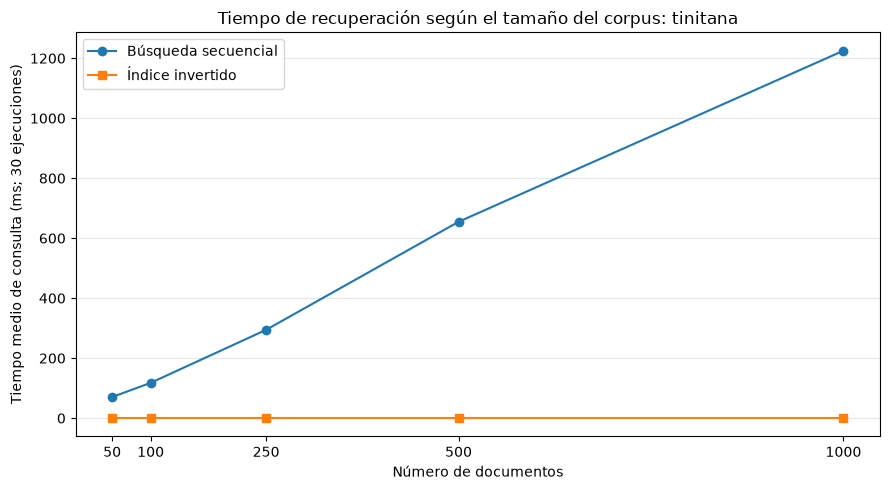

In [19]:
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd

tamanos_8 = [50, 100, 250, 500, 1000]
consulta_8 = "tinitana"

if "corpus_grande" not in globals() or len(corpus_grande) < max(tamanos_8):
    raise ValueError("Ejecuta primero el punto 7 hasta completar 1.000 documentos.")


documentos_8 = list(corpus_grande.items())
registros_8 = []

for n in tamanos_8:
    subconjunto_8 = dict(documentos_8[:n])
    total_tokens_8 = sum(len(tokens) for tokens in subconjunto_8.values())

    buscar_secuencial_8 = partial(busqueda_secuencial, corpus=subconjunto_8)
    tiempo_secuencial_8 = medir_consulta(
        buscar_secuencial_8, consulta_8, repeticiones=30
    )

    indice_8 = construir_indice(subconjunto_8)


    buscar_indice_8 = partial(consulta_termino, indice=indice_8)
    tiempo_indice_8 = medir_consulta(
        buscar_indice_8, consulta_8, repeticiones=30
    )

    registros_8.append({
        "Documentos": n,
        "Tokens": total_tokens_8,
        "Consulta": consulta_8,
        "Secuencial_ms": tiempo_secuencial_8,
        "Indice_ms": tiempo_indice_8,
    })

    print(f"Medición terminada: {n} documentos.", flush=True)
    del buscar_indice_8, indice_8

resultados_8 = pd.DataFrame(registros_8)

carpeta_resultados_8 = root_dir / "data" / "large_gutenberg"
resultados_8.to_csv(
    carpeta_resultados_8 / "resultados_punto8.csv",
    index=False,
)

display(resultados_8.round(6))

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    resultados_8["Documentos"],
    resultados_8["Secuencial_ms"],
    marker="o",
    label="Búsqueda secuencial",
)
ax.plot(
    resultados_8["Documentos"],
    resultados_8["Indice_ms"],
    marker="s",
    label="Índice invertido",
)

ax.set_xlabel("Número de documentos")
ax.set_ylabel("Tiempo medio de consulta (ms; 30 ejecuciones)")
ax.set_title(f"Tiempo de recuperación según el tamaño del corpus: {consulta_8}")
ax.set_xticks(tamanos_8)
ax.grid(axis="y", alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(carpeta_resultados_8 / "grafica_punto8.png", dpi=180)
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

Búsqueda secuencial: t(n) = (1.233306007)*n + (3.811457479) ms; R² = 0.998110
Índice invertido: t(n) = (1.802100608e-08)*n + (0.001081818684) ms; R² = 0.087597


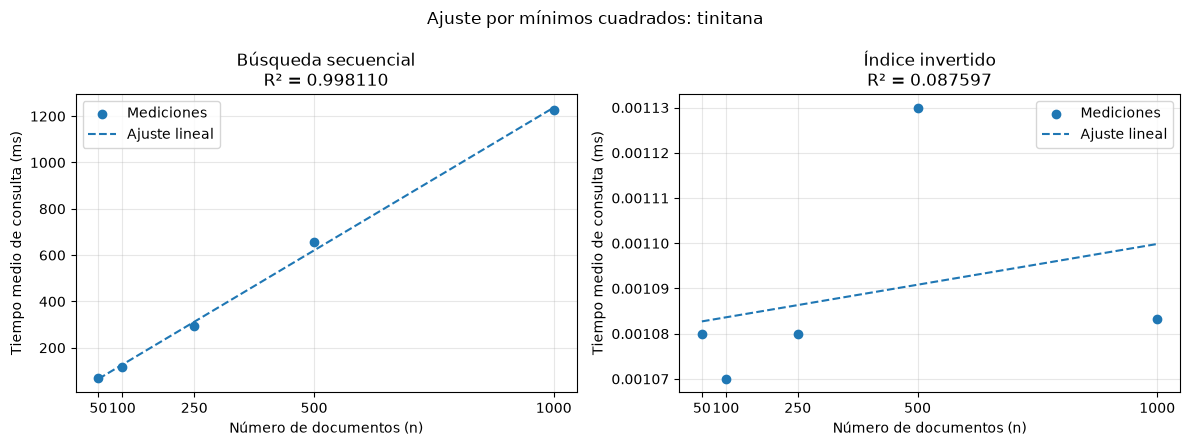

,Método,a_ms_por_documento,b_ms,R2
0,Búsqueda secuencial,1.233306e+00,3.811457,0.998110
1,Índice invertido,1.802101e-08,0.001082,0.087597


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

carpeta_resultados_9 = root_dir / "data" / "large_gutenberg"

if "resultados_8" in globals():
    datos_9 = resultados_8.copy()
else:
    datos_9 = pd.read_csv(
        carpeta_resultados_9 / "resultados_punto8.csv"
    )

datos_9 = datos_9.sort_values("Documentos")

if datos_9["Consulta"].nunique() != 1:
    raise ValueError("Todos los tamaños deben corresponder a la misma consulta.")

n_9 = datos_9["Documentos"].to_numpy(dtype=float)


def ajustar_recta(n, tiempos):
    if not np.isfinite(n).all() or not np.isfinite(tiempos).all():
        raise ValueError("Los datos contienen valores no finitos.")

    a, b = np.polyfit(n, tiempos, deg=1)
    predicciones = a * n + b

    suma_residuos = np.sum((tiempos - predicciones) ** 2)
    suma_total = np.sum((tiempos - tiempos.mean()) ** 2)

    if np.all(tiempos == tiempos[0]):
        r2 = np.nan
    else:
        r2 = 1 - suma_residuos / suma_total

    return a, b, r2


metodos_9 = {
    "Búsqueda secuencial": "Secuencial_ms",
    "Índice invertido": "Indice_ms",
}

registros_9 = []
n_curva_9 = np.linspace(n_9.min(), n_9.max(), 200)
fig, ejes_9 = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (metodo, columna) in zip(ejes_9, metodos_9.items()):
    tiempos = datos_9[columna].to_numpy(dtype=float)
    a, b, r2 = ajustar_recta(n_9, tiempos)

    registros_9.append({
        "Método": metodo,
        "a_ms_por_documento": a,
        "b_ms": b,
        "R2": r2,
    })

    print(
        f"{metodo}: t(n) = ({a:.10g})*n + ({b:.10g}) ms; "
        f"R² = {r2:.6f}"
    )

    ax.scatter(n_9, tiempos, label="Mediciones", zorder=3)
    ax.plot(
        n_curva_9,
        a * n_curva_9 + b,
        "--",
        label="Ajuste lineal",
    )
    ax.set_title(f"{metodo}\nR² = {r2:.6f}")
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio de consulta (ms)")
    ax.set_xticks(n_9.astype(int))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    f"Ajuste por mínimos cuadrados: {datos_9['Consulta'].iloc[0]}"
)
fig.tight_layout()
fig.savefig(
    carpeta_resultados_9 / "ajustes_punto9.png",
    dpi=180,
)
plt.show()

ajustes_9 = pd.DataFrame(registros_9)
ajustes_9.to_csv(
    carpeta_resultados_9 / "ajustes_punto9.csv",
    index=False,
)
display(ajustes_9)

Para la búsqueda secuencial se obtuvo:

$$
t(n)=1{,}233306007n+3{,}811457479
$$

con el tiempo expresado en milisegundos y un
$R^2=0{,}998110$. La recta sigue de cerca los puntos medidos, así que
describe bien el comportamiento observado en estos cinco tamaños.

La consulta utilizada fue “tinitana”, que no aparece en los subconjuntos.
Por eso la búsqueda secuencial debe recorrer todos los tokens antes
de devolver un resultado vacío. Su costo es $O(T)$, donde $T$ es el
total de tokens. El crecimiento se ve aproximadamente lineal respecto
al número de documentos, aunque también depende de cuánto mida
cada libro.

Para el índice invertido se obtuvo:

$$
t(n)=0{,}00000001802100608n+0{,}001081818684
$$

con un $R^2=0{,}087597$. Aquí la recta explica poco las pequeñas
variaciones entre mediciones. Aun así, los tiempos se mantienen
alrededor de 0,00108 milisegundos, aproximadamente 1,08 microsegundos,
y la pendiente es casi cero.

El índice puede comprobar que el término no existe mediante una
búsqueda en el diccionario, sin recorrer los libros. Esto es compatible
con un costo promedio aproximadamente constante para esta consulta.
El bajo R² no significa que el índice funcione mal; indica que aumentar
el número de documentos explica poco las fluctuaciones observadas.

Estos resultados corresponden a un término inexistente. Una consulta
que recupere muchos documentos también debe devolver y ordenar
sus identificadores, por lo que su costo puede aumentar. Tampoco se
incluyó la construcción del índice dentro de los tiempos de consulta.

Las dos gráficas del ajuste utilizan escalas verticales diferentes para
que puedan verse las variaciones de cada método.